In [1]:
%load_ext autoreload
%autoreload 2

import open3d as o3d
import numpy as np
import os
import sys
from glob import glob
import pickle
import pandas as pd
from pathlib import Path
import json

import networkx as nx
import plotly.express as px

import sys
sys.path.append('D:\Dev\Point-Cloud-Registration\source')
from utils.write_output import write_array2txt
from utils.math_methods import calc_overlap_curve, cart2pol

from cylinder_extraction.cylinder import Cylinder
from cylinder_extraction.station import Station
from cylinder_alignment.utils import draw_thin_slice
from registration.utils import multiway_load_point_clouds as load_point_clouds

# from registration.utils import multiway_full_registration as full_registration
# from registration.utils import pairwise_registration, combine_point_cloud, multiway_filter_point_clouds

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


# READ data from rough alignment phase 1 and get a thin slice

In [2]:
data_dir = Path('D:/REGISTRATION DATA/External/JB-531 40ft EXT')
with open(os.path.join(data_dir, 'globalization_axis_phase_1.pkl'), 'rb') as f:
    bundle = pickle.load(f)
    
# points = np.empty([1,4])
# for ind, c in enumerate(bundle.target_tank):
#     c.update_filepath(new_dir=data_dir / 'target_tank' / 'global' / 'thin_slice', num_keep_level=1)
#     c.read_points()
#     # accumulate
#     points = np.r_[points, np.c_[c.points, ind * np.ones([c.points.shape[0],1])]]

# Visualise these slices

In [3]:
_ = bundle.draw_alignment_phase_1b()

[(3, 5), (0, 1), (6, 5), (2, 5), (0, 7), (1, 4), (4, 2)]

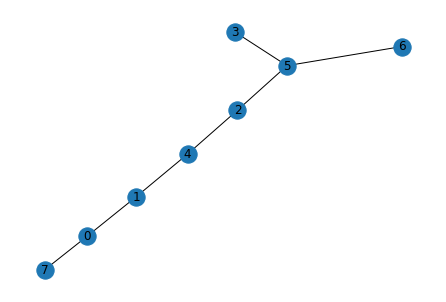

In [4]:
edgelist = bundle.determine_pairing_sequence(visual=True, ignore_station_ids=[])
edgelist